In [1]:
import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pvlib
import os
import warnings
warnings.filterwarnings('ignore')

try:
    pd.options.future.infer_string = False
except Exception:
    pass

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size']        = 11

base = os.path.join(os.path.expanduser("~"), "Documents", "EdenCampus_PhD")

# ── REBUILD TIME INDEX & INPUT DATA ──
winter = pd.date_range('2023-01-09', periods=168, freq='h')
spring = pd.date_range('2023-04-10', periods=168, freq='h')
summer = pd.date_range('2023-07-10', periods=168, freq='h')
autumn = pd.date_range('2023-10-09', periods=168, freq='h')
time_index = winter.append(spring).append(summer).append(autumn)

print("Downloading PV data from PVGIS...")
result       = pvlib.iotools.get_pvgis_hourly(
    latitude=56.3398, longitude=-2.7967,
    start=2023, end=2023, map_variables=True)
weather_2023 = result[0]
weather_2023.index = weather_2023.index.tz_localize(None)
weather_2023.index = weather_2023.index.round('h')
weather_2023 = weather_2023[~weather_2023.index.duplicated(keep='first')]

weather_2023['poa_total'] = (
    weather_2023['poa_direct'] +
    weather_2023['poa_sky_diffuse'] +
    weather_2023['poa_ground_diffuse'])

pv_output_kW = 1000 * (weather_2023['poa_total'] / 1000) * (
    1 + (-0.004) * (weather_2023['temp_air'] - 25))
pv_output_kW    = pv_output_kW.clip(lower=0)
pv_profile_full = (pv_output_kW / 1000).clip(0, 1)
pv_profile      = pv_profile_full.reindex(time_index).fillna(0)

np.random.seed(42)

def generate_elec_demand(timestamp):
    hour   = timestamp.hour
    month  = timestamp.month
    day    = timestamp.weekday()
    seasonal = {1:1.3, 2:1.25, 3:1.1, 4:1.0, 5:0.95, 6:0.9,
                7:0.9, 8:0.9, 9:1.0, 10:1.1, 11:1.2, 12:1.3}
    hourly_profile = {
        0:0.1, 1:0.1, 2:0.1, 3:0.1, 4:0.1, 5:0.15,
        6:0.2, 7:0.4, 8:0.7, 9:0.9, 10:1.0, 11:1.0,
        12:0.85, 13:0.9, 14:1.0, 15:0.95, 16:0.85, 17:0.7,
        18:0.5, 19:0.35, 20:0.25, 21:0.2, 22:0.15, 23:0.1}
    base_d         = 150
    peak           = 500
    season_factor  = seasonal[month]
    weekend_factor = 0.3 if day >= 5 else 1.0
    hour_factor    = hourly_profile[hour]
    demand = (base_d + (peak - base_d) * hour_factor) * season_factor * weekend_factor
    return demand * np.random.uniform(0.95, 1.05)

def generate_thermal_demand(timestamp):
    hour   = timestamp.hour
    month  = timestamp.month
    day    = timestamp.weekday()
    seasonal_thermal = {
        1:1.8, 2:1.6, 3:1.3, 4:0.8, 5:0.4, 6:0.2,
        7:0.2, 8:0.2, 9:0.5, 10:0.9, 11:1.4, 12:1.7}
    hourly_thermal = {
        0:0.3, 1:0.2, 2:0.2, 3:0.2, 4:0.2, 5:0.3,
        6:0.5, 7:0.8, 8:1.0, 9:1.0, 10:1.0, 11:1.0,
        12:0.9, 13:0.95, 14:1.0, 15:1.0, 16:0.9, 17:0.8,
        18:0.6, 19:0.5, 20:0.4, 21:0.35, 22:0.3, 23:0.3}
    season_factor  = seasonal_thermal[month]
    weekend_factor = 0.25 if day >= 5 else 1.0
    hour_factor    = hourly_thermal[hour]
    peak_thermal   = 400
    base_thermal   = 80
    demand = (base_thermal + (peak_thermal - base_thermal) *
              hour_factor) * season_factor * weekend_factor
    return max(demand * np.random.uniform(0.95, 1.05), 0)

elec_demand    = pd.Series(
    [generate_elec_demand(ts)   for ts in time_index],
    index=time_index)
thermal_demand = pd.Series(
    [generate_thermal_demand(ts) for ts in time_index],
    index=time_index)

print(f"PV peak: {pv_profile.max()*100:.1f}%  |  "
      f"Elec peak: {elec_demand.max():.0f} kW  |  "
      f"Thermal peak: {thermal_demand.max():.0f} kW")
print("Input data ready.")

PV peak: 80.5%  |  Elec peak: 681 kW  |  Thermal peak: 755 kW
Input data ready.


In [2]:
def build_and_run_scenario(name, use_bess=False, use_pcm=False,
                            use_h2=False, use_heatpump=False):
    n = pypsa.Network()
    n.set_snapshots(time_index)

    # ── Carriers ──
    n.add("Carrier", "AC",       co2_emissions=0.233)
    n.add("Carrier", "hydrogen", co2_emissions=0.0)
    n.add("Carrier", "heat",     co2_emissions=0.0)

    # ── Buses ──
    n.add("Bus", "Electricity Bus", carrier="AC")
    if use_h2:
        n.add("Bus", "Hydrogen Bus", carrier="hydrogen")
    if use_pcm or use_heatpump:
        n.add("Bus", "Heat Bus", carrier="heat")

    # ── Solar PV ──
    n.add("Generator", "Solar PV",
          bus="Electricity Bus", carrier="AC",
          p_nom=1000, p_max_pu=pv_profile,
          marginal_cost=0)

    # ── Grid ──
    n.add("Generator", "Grid Import",
          bus="Electricity Bus", carrier="AC",
          p_nom=2000, marginal_cost=280)
    n.add("Generator", "Grid Export",
          bus="Electricity Bus", carrier="AC",
          p_nom=500, p_max_pu=0, p_min_pu=-1,
          marginal_cost=-50)

    # ── BESS ──
    if use_bess:
        n.add("StorageUnit", "BESS",
              bus="Electricity Bus", carrier="AC",
              p_nom=500, max_hours=4,
              efficiency_store=0.95, efficiency_dispatch=0.95,
              standing_loss=0.0002, cyclic_state_of_charge=True)

    # ── Hydrogen LDES ──
    if use_h2:
        n.add("Link", "Electrolyser",
              bus0="Electricity Bus", bus1="Hydrogen Bus",
              p_nom=200, efficiency=0.70, marginal_cost=1)
        n.add("Link", "Fuel Cell",
              bus0="Hydrogen Bus", bus1="Electricity Bus",
              p_nom=100, efficiency=0.50, marginal_cost=2)
        n.add("Store", "Hydrogen Tank",
              bus="Hydrogen Bus", carrier="hydrogen",
              e_nom=5000, e_cyclic=True,
              standing_loss=0.0001)

    # ── Electrical Demand ──
    n.add("Load", "Electrical Demand",
          bus="Electricity Bus", carrier="AC",
          p_set=elec_demand)

    # ── Heat system ──
    if use_pcm or use_heatpump:
        n.add("Generator", "Backup Boiler",
              bus="Heat Bus", carrier="heat",
              p_nom=600, marginal_cost=110)
        n.add("Load", "Thermal Demand",
              bus="Heat Bus", carrier="heat",
              p_set=thermal_demand)
        if use_heatpump:
            n.add("Link", "Heat Pump",
                  bus0="Electricity Bus", bus1="Heat Bus",
                  p_nom=300, efficiency=3.0, marginal_cost=0.5)
        if use_pcm:
            n.add("StorageUnit", "PCM TES",
                  bus="Heat Bus", carrier="heat",
                  p_nom=200, max_hours=8,
                  efficiency_store=0.95, efficiency_dispatch=0.92,
                  standing_loss=0.001, cyclic_state_of_charge=True)

    # ── Solve ──
    n.optimize(solver_name='highs')

    # ── Extract KPIs ──
    pv_gen        = n.generators_t.p["Solar PV"]
    grid_import   = n.generators_t.p["Grid Import"]
    grid_export   = n.generators_t.p["Grid Export"].abs()
    total_pv      = pv_gen.sum()
    total_demand  = elec_demand.sum()
    total_import  = grid_import.sum()
    total_export  = grid_export.sum()
    pv_consumed   = total_pv - total_export
    self_consump  = (pv_consumed / total_pv * 100) if total_pv > 0 else 0
    solar_frac    = (pv_consumed / total_demand * 100) if total_demand > 0 else 0
    peak_baseline = elec_demand.max()
    peak_with     = grid_import.max()
    peak_red      = ((peak_baseline - peak_with) / peak_baseline * 100)
    co2_saved     = (pv_consumed * 0.233) / 1000
    total_cost    = n.objective

    return {
        'Scenario':               name,
        'PV Generation (MWh)':    round(total_pv    / 1000, 1),
        'Grid Import (MWh)':      round(total_import / 1000, 1),
        'Grid Export (MWh)':      round(total_export / 1000, 1),
        'Self-Consumption (%)':   round(self_consump, 1),
        'Solar Fraction (%)':     round(solar_frac,   1),
        'Peak Reduction (%)':     round(peak_red,     1),
        'CO2 Saved (tonnes)':     round(co2_saved,    1),
        'Total Cost (£k)':        round(total_cost / 1000, 1),
    }

print("Running all 5 scenarios — please wait...")
print("=" * 55)

scenarios_config = [
    ("S0: PV Only",          False, False, False, False),
    ("S1: PV + BESS",        True,  False, False, False),
    ("S2: PV + PCM TES",     False, True,  False, True),
    ("S3: PV + H2 LDES",     False, False, True,  False),
    ("S4: Full Hybrid",      True,  True,  True,  True),
]

results = []
for name, bess, pcm, h2, hp in scenarios_config:
    print(f"  Running {name}...")
    r = build_and_run_scenario(name, bess, pcm, h2, hp)
    results.append(r)
    print(f"    Cost: £{r['Total Cost (£k)']:.0f}k  |  "
          f"Solar: {r['Solar Fraction (%)']:.1f}%  |  "
          f"CO2: {r['CO2 Saved (tonnes)']:.1f}t")

results_df = pd.DataFrame(results).set_index('Scenario')
print("\n" + "=" * 55)
print("ALL SCENARIOS COMPLETE")
print("=" * 55)
print(results_df.to_string())

Running all 5 scenarios — please wait...
  Running S0: PV Only...


INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.09s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 2016 primals, 4704 duals
Objective: 3.41e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-g48wbh7j has 4704 rows; 2016 cols; 6048 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
124 rows, 372 cols, 372 nonzeros  0s
Dependent equations search running on 117 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
117 rows, 351 cols, 351 nonzeros  0s
Presolve reductions: rows 117(-4587); columns 351(-1665); nonzeros 351(-5697) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     3.4114473748e+07 Pr: 117(31968) 0.0s
        117     3.4114473748e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-g48wbh7j
Model status        : Optimal
Simplex   iterations: 117
Ob

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.02e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-3g38xfhc has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1302 rows, 3577 cols, 5509 nonzeros  0s
Dependent equations search running on 1302 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1302 rows, 3577 cols, 5509 nonzeros  0s
Presolve reductions: rows 1302(-8106); columns 3577(-455); nonzeros 5509(-8603) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1820     3.0217157992e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-3g38xfhc
Model status        : Optimal
Simplex   iterations: 1

...

Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-fcqy01dz has 12768 rows; 5376 cols; 18816 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 3e+00]
  Cost    [5e-01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1468 rows, 3732 cols, 5872 nonzeros  0s
Dependent equations search running on 1263 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1263 rows, 3004 cols, 4734 nonzeros  0s
Presolve reductions: rows 1263(-11505); columns 3004(-2372); nonzeros 4734(-14082) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1614     4.4848481316e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-fcqy01dz
Model status        : Optimal
Simplex   iteration

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4704 primals, 10080 duals
Objective: 3.25e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, Store-fix-e-lower, Store-fix-e-upper, Store-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-d33m6cwi has 10080 rows; 4704 cols; 15456 nonzeros
Coefficient ranges:
  Matrix  [5e-01, 1e+00]
  Cost    [1e+00, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 5e+03]
Presolving model
1492 rows, 3127 cols, 4767 nonzeros  0s
820 rows, 2455 cols, 3423 nonzeros  0s
Dependent equations search running on 820 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
820 rows, 2455 cols, 3423 nonzeros  0s
Presolve reductions: rows 820(-9260); columns 2455(-2249); nonzeros 3423(-12033) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
        926     3.2489322052e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-d33m6cwi
Model status  

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|█████████████████████████████████████████████████████| 7/7 [00:00<00:00, 916.13it/s]
INFO:linopy.io: Writing time: 0.06s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 10080 primals, 22848 duals
Objective: 4.15e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, Store-fix-e-lower, Store-fix-e-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance, Store-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-o6zxa2z9 has 22848 rows; 10080 cols; 36288 nonzeros
Coefficient ranges:
  Matrix  [5e-01, 3e+00]
  Cost    [5e-01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 5e+03]
Presolving model
4032 rows, 9695 cols, 17087 nonzeros  0s
Dependent equations search running on 3329 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
3329 rows, 8985 cols, 15571 nonzeros  0s
Presolve reductions: rows 3329(-19519); columns 8985(-1095); nonzeros 15571(-20717) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       4599     4.1536978928e+07 Pr: 0(0); Du: 0(1.2204e-13) 0.1s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-o6zxa2z9
Model status        : Opti

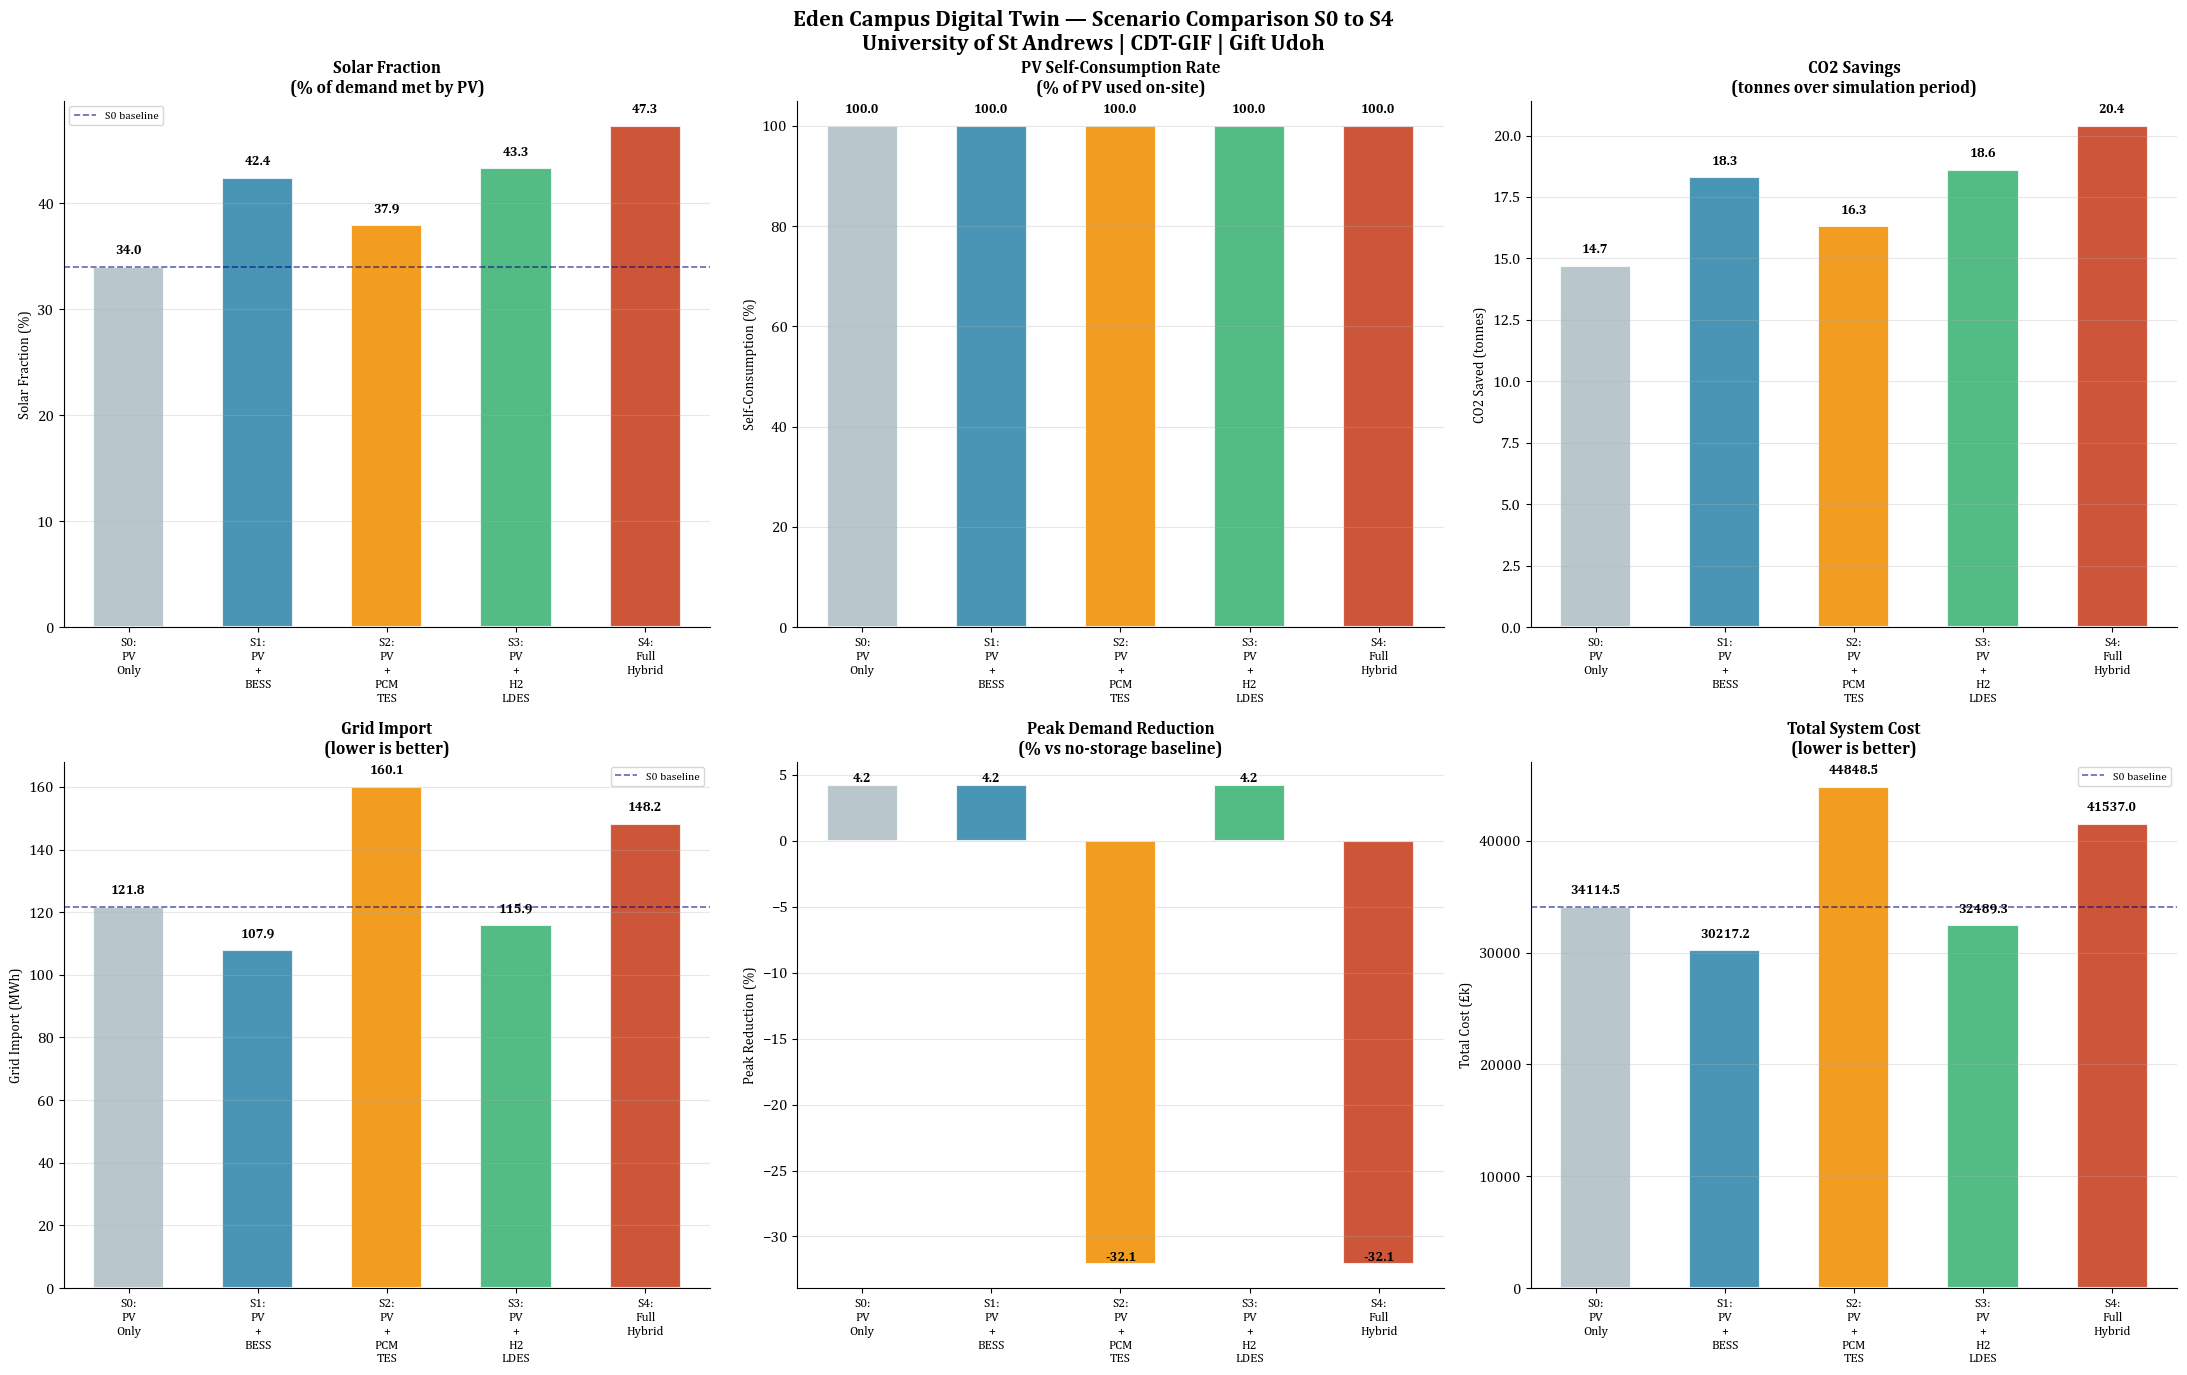

Scenario comparison chart saved!


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(22, 14))
fig.suptitle(
    'Eden Campus Digital Twin — Scenario Comparison S0 to S4\n'
    'University of St Andrews | CDT-GIF | Gift Udoh',
    fontsize=16, fontweight='bold')

scenarios  = results_df.index.tolist()
bar_colors = ['#B0BEC5', '#2E86AB', '#F18F01', '#3BB273', '#C73E1D']
x          = np.arange(len(scenarios))
width      = 0.55

def bar_chart(ax, metric, title, ylabel, color_list, annotate=True):
    values = results_df[metric].values
    bars   = ax.bar(x, values, width, color=color_list,
                    edgecolor='white', linewidth=1.5, alpha=0.88)
    if annotate:
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + abs(max(values)) * 0.02,
                    f'{val:.1f}', ha='center', va='bottom',
                    fontsize=9.5, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels([s.replace(' ', '\n') for s in scenarios],
                        fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

bar_chart(axes[0, 0], 'Solar Fraction (%)',
          'Solar Fraction\n(% of demand met by PV)',
          'Solar Fraction (%)', bar_colors)

bar_chart(axes[0, 1], 'Self-Consumption (%)',
          'PV Self-Consumption Rate\n(% of PV used on-site)',
          'Self-Consumption (%)', bar_colors)

bar_chart(axes[0, 2], 'CO2 Saved (tonnes)',
          'CO2 Savings\n(tonnes over simulation period)',
          'CO2 Saved (tonnes)', bar_colors)

bar_chart(axes[1, 0], 'Grid Import (MWh)',
          'Grid Import\n(lower is better)',
          'Grid Import (MWh)', bar_colors)

bar_chart(axes[1, 1], 'Peak Reduction (%)',
          'Peak Demand Reduction\n(% vs no-storage baseline)',
          'Peak Reduction (%)', bar_colors)

bar_chart(axes[1, 2], 'Total Cost (£k)',
          'Total System Cost\n(lower is better)',
          'Total Cost (£k)', bar_colors)

# ── Add S0 baseline reference line on relevant charts ──
s0_solar  = results_df.loc['S0: PV Only', 'Solar Fraction (%)']
s0_cost   = results_df.loc['S0: PV Only', 'Total Cost (£k)']
s0_import = results_df.loc['S0: PV Only', 'Grid Import (MWh)']

for ax, val in [
    (axes[0, 0], s0_solar),
    (axes[1, 0], s0_import),
    (axes[1, 2], s0_cost),
]:
    ax.axhline(val, color='navy', linewidth=1.2,
               linestyle='--', alpha=0.6, label='S0 baseline')
    ax.legend(fontsize=8)

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures",
                          "scenario_comparison_S0_S4.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print("Scenario comparison chart saved!")

In [4]:
import openpyxl

# ── Save as Excel ──
excel_path = os.path.join(base, "04_results/tables",
                           "scenario_comparison_S0_S4.xlsx")
os.makedirs(os.path.join(base, "04_results/tables"), exist_ok=True)
results_df.to_excel(excel_path)
print(f"Excel table saved: {excel_path}")

# ── Print LaTeX table for thesis ──
print("\n── LaTeX Table (copy into thesis) ──\n")
print(results_df.to_latex(
    caption='Scenario comparison KPIs for Eden Campus digital twin.',
    label='tab:scenario_comparison',
    float_format='{:.1f}'.format))

# ── Print summary of best scenario per KPI ──
print("\n── Best Scenario per KPI ──")
for col in results_df.columns:
    if 'Cost' in col or 'Import' in col:
        best = results_df[col].idxmin()
        val  = results_df[col].min()
    else:
        best = results_df[col].idxmax()
        val  = results_df[col].max()
    print(f"  {col:<30} → {best}  ({val:.1f})")

Excel table saved: /Users/everythingkrypto/Documents/EdenCampus_PhD/04_results/tables/scenario_comparison_S0_S4.xlsx

── LaTeX Table (copy into thesis) ──

\begin{table}
\caption{Scenario comparison KPIs for Eden Campus digital twin.}
\label{tab:scenario_comparison}
\begin{tabular}{lrrrrrrrr}
\toprule
 & PV Generation (MWh) & Grid Import (MWh) & Grid Export (MWh) & Self-Consumption (%) & Solar Fraction (%) & Peak Reduction (%) & CO2 Saved (tonnes) & Total Cost (£k) \\
Scenario &  &  &  &  &  &  &  &  \\
\midrule
S0: PV Only & 62.9 & 121.8 & 0.0 & 100.0 & 34.0 & 4.2 & 14.7 & 34114.5 \\
S1: PV + BESS & 78.3 & 107.9 & 0.0 & 100.0 & 42.4 & 4.2 & 18.3 & 30217.2 \\
S2: PV + PCM TES & 70.0 & 160.1 & 0.0 & 100.0 & 37.9 & -32.1 & 16.3 & 44848.5 \\
S3: PV + H2 LDES & 79.9 & 115.9 & 0.0 & 100.0 & 43.3 & 4.2 & 18.6 & 32489.3 \\
S4: Full Hybrid & 87.4 & 148.2 & 0.0 & 100.0 & 47.3 & -32.1 & 20.4 & 41537.0 \\
\bottomrule
\end{tabular}
\end{table}


── Best Scenario per KPI ──
  PV Generation (MWh)   